# Elastic constants of a crystal, and the Debye and Einstein models

A crystal resists being stretched and sheared. Its **elastic constants** say how
much stress a small strain costs, and they also set the **speed of sound**. Debye's
model of a solid replaces all lattice vibrations by sound waves up to a cut-off
frequency; Einstein's lets every atom vibrate on its own at one frequency.

Here a Lennard-Jones crystal (argon, in reduced units) is strained a little at a low
temperature, the stress is measured, and the elastic constants give a Debye
temperature. The atoms' own vibrations, from their velocities, show how well Debye
and Einstein describe the real spectrum, and what each predicts for the heat
capacity.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fys2160_md import FCC, MDSimulation

## A crystal at zero pressure

An FCC crystal of 500 atoms at $T^* = 0.1$, first with a barostat at zero pressure,
so that the box finds its natural size at this temperature.

In [2]:
crystal = FCC(N=500, rho=1.05)
relax = MDSimulation(
    pair_potential="lj",
    epsilon=1,
    sigma=1,
    ensemble="npt",
    temperature=0.1,
    pressure=0.0,
    timestep=0.005,
    cutoff=2.5,
    friction=0.5,
)
relaxed = relax.run(crystal, steps=20000, thermo_every=100, trajectory_every=None, storage_name="relax")
volume = relaxed.thermo["volume"][50:].mean()
print(f"density at zero pressure: {500/volume:.4f}")

density at zero pressure: 1.0586


Take the final state and stretch it, atoms and all, to the mean volume, so that it
starts at zero pressure. From here on the box is fixed (`nvt`).

In [3]:
state = relaxed.state
stretch = (volume/state.box.volume)**(1/3) - 1
state.strain(xx=stretch, yy=stretch, zz=stretch)
sim = MDSimulation(
    pair_potential="lj",
    epsilon=1,
    sigma=1,
    ensemble="nvt",
    temperature=0.1,
    timestep=0.005,
    cutoff=2.5,
    friction=0.5,
)

## Strain and stress

`state.strain(xx=e)` makes the box (and the crystal in it) longer along x by a
fraction $e$; `state.strain(xy=e)` shears it, leaning the y edges along x. Each run
records the pressure tensor; the stress is its negative. For a cubic crystal three
constants describe the response:

$$C_{11} = -\frac{\Delta p_{xx}}{\Delta \varepsilon_{xx}}, \quad
C_{12} = -\frac{\Delta p_{yy}}{\Delta \varepsilon_{xx}}, \quad
C_{44} = -\frac{\Delta p_{xy}}{\Delta \gamma_{xy}}$$

Straining by $+e$ and $-e$ and taking the difference removes the stress the crystal
had to begin with.

A strain of 1% is too small to see. Here is the same shear twenty times larger,
seen from above: the y edges of the box lean along x, and the crystal leans with them.

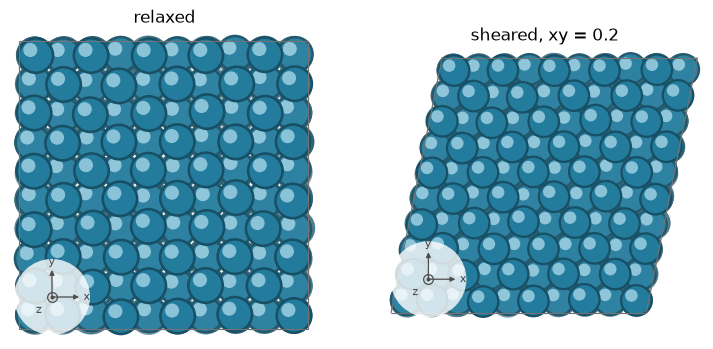

In [4]:
picture = state.copy()
picture.strain(xy=0.2)
fig, (before, after) = plt.subplots(1, 2, figsize=(9, 4))
state.draw(ax=before, view="top", projection="orthographic")
picture.draw(ax=after, view="top", projection="orthographic")
before.set_title("relaxed")
after.set_title("sheared, xy = 0.2")
plt.show()

In [5]:
e = 0.01
stress = {}
for name, strain in [("stretched", dict(xx=e)), ("compressed", dict(xx=-e)),
                     ("sheared", dict(xy=e)), ("sheared back", dict(xy=-e))]:
    strained = state.copy()
    strained.strain(**strain)
    run = sim.run(strained, steps=20000, thermo_every=10, trajectory_every=None, storage_name=name)
    stress[name] = run.thermo[200:].mean()  # after the first 2000 steps

C11 = -(stress["stretched"]["pxx"] - stress["compressed"]["pxx"])/(2*e)
C12 = -(stress["stretched"]["pyy"] - stress["compressed"]["pyy"])/(2*e)
C44 = -(stress["sheared"]["pxy"] - stress["sheared back"]["pxy"])/(2*e)
print(f"C11 = {C11:.1f}, C12 = {C12:.1f}, C44 = {C44:.1f}  (units of epsilon/sigma^3)")

C11 = 81.5, C12 = 47.8, C44 = 49.5  (units of epsilon/sigma^3)


For atoms that only interact in pairs, $C_{12} = C_{44}$ at zero temperature and
pressure (the *Cauchy relation*); here they are close. Real argon satisfies it
nearly as well; metals do not.

## From elastic constants to a Debye temperature

The bulk modulus $K$ and an average shear modulus $G$ (the Voigt–Reuss–Hill average
over directions) give the speeds of longitudinal and transverse sound,
$v_l = \sqrt{(K + 4G/3)/\rho}$ and $v_t = \sqrt{G/\rho}$. Debye's model uses
one mean speed, $3/v_D^3 = 1/v_l^3 + 2/v_t^3$, and a cut-off frequency at which the
crystal has used up all its $3N$ vibrations:
$\omega_D = v_D\,(6\pi^2 n)^{1/3}$, with $n$ the number density.
The Debye temperature is $\theta_D = \hbar\omega_D/k_B$.

In [6]:
n = 500/volume                      # number density; with m = 1 also the mass density
K = (C11 + 2*C12)/3
G = ((C11 - C12 + 3*C44)/5 + 5*(C11 - C12)*C44/(4*C44 + 3*(C11 - C12)))/2
v_l, v_t = np.sqrt((K + 4*G/3)/n), np.sqrt(G/n)
v_D = (np.mean([1/v_l**3, 1/v_t**3, 1/v_t**3]))**(-1/3)
omega_D = v_D*(6*np.pi**2*n)**(1/3)
print(f"v_l = {v_l:.2f}, v_t = {v_t:.2f}, omega_D = {omega_D:.1f}  (reduced units)")

v_l = 9.81, v_t = 5.51, omega_D = 24.4  (reduced units)


Reduced units hide $\hbar$. For argon, $\sigma = 3.405$ Å, $\epsilon/k_B = 119.8$ K and
$m = 39.95$ u, so the reduced Planck constant is $\hbar^* = \hbar/(\sigma\sqrt{m\epsilon})$:

In [7]:
hbar, k_B, u = 1.054571817e-34, 1.380649e-23, 1.66053907e-27
sigma, epsilon, mass = 3.405e-10, 119.8*k_B, 39.95*u
hbar_reduced = hbar/(sigma*np.sqrt(mass*epsilon))
theta_D = hbar_reduced*omega_D*119.8    # in K: hbar*omega/k_B, with epsilon/k_B = 119.8 K
print(f"hbar* = {hbar_reduced:.4f}, Debye temperature of the model: {theta_D:.0f} K")

hbar* = 0.0296, Debye temperature of the model: 86 K


Measured heat capacities of solid argon give a Debye temperature of about 92 K, so
a pair potential and a few thousand MD steps come close.

## The vibrations themselves

The velocities of vibrating atoms contain all their frequencies. The power
spectrum of the velocities (the Fourier transform of their autocorrelation) is the
**density of vibrational states** $g(\omega)$, normalised here to $3N$ modes. The
run is at constant energy, so the thermostat does not disturb the motion.

In [8]:
live = sim.start(state, ensemble="nve")
live.advance(2000)
velocities = []
for _ in range(4096):
    live.advance(2)
    velocities.append(live.velocities)
velocities = np.array(velocities)          # (time, atoms, 3)

dt = 2*0.005
power = (np.abs(np.fft.rfft(velocities, axis=0))**2).sum(axis=(1, 2))
omega = 2*np.pi*np.fft.rfftfreq(len(velocities), dt)
g = 3*500*power/np.trapezoid(power, omega)

Einstein's single frequency follows from how far the atoms stray from their
lattice sites: for a classical harmonic oscillator,
$\langle u^2 \rangle = 3k_BT/(m\omega_E^2)$.

In [9]:
sites = sim.run(state, steps=4000, thermo_every=100, trajectory_every=10, storage_name="sites")
positions = sites.unwrapped                 # (saved steps, atoms, 3), not wrapped into the box
mean_square = ((positions - positions.mean(axis=0))**2).sum(axis=2).mean()
omega_E = np.sqrt(3*0.1/mean_square)
print(f"<u^2> = {mean_square:.5f}, omega_E = {omega_E:.1f}, Einstein temperature {hbar_reduced*omega_E*119.8:.0f} K")

<u^2> = 0.00151, omega_E = 14.1, Einstein temperature 50 K


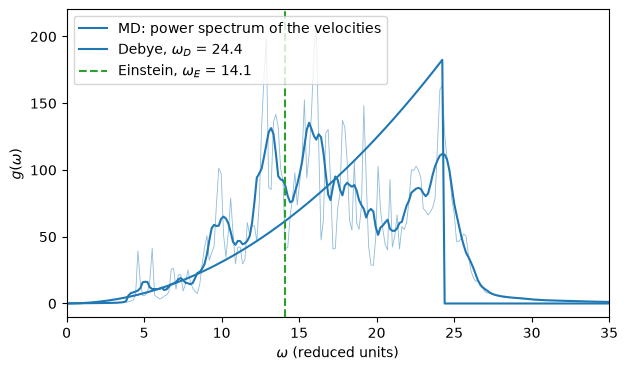

In [10]:
debye = np.where(omega < omega_D, 9*500*omega**2/omega_D**3, 0)
smooth = np.convolve(g, np.ones(9)/9, mode="same")   # a running mean over 9 frequencies
plt.figure(figsize=(7, 4))
plt.plot(omega, g, color="C0", lw=0.6, alpha=0.5)
plt.plot(omega, smooth, color="C0", label="MD: power spectrum of the velocities")
plt.plot(omega, debye, label=f"Debye, $\\omega_D$ = {omega_D:.1f}")
plt.axvline(omega_E, color="C2", ls="--", label=f"Einstein, $\\omega_E$ = {omega_E:.1f}")
plt.xlim(0, 35)
plt.xlabel("$\\omega$ (reduced units)")
plt.ylabel("$g(\\omega)$")
plt.legend()
plt.show()

Debye's $\omega^2$ law fits the low frequencies, the long sound waves, and puts all
modes below one cut-off; the real spectrum has two peaks, from transverse and
longitudinal waves near the edge of the Brillouin zone. Einstein's frequency sits
in the middle. The thin line has sharp peaks because a crystal of 500 atoms only has
room for a finite set of wavelengths; the thick line is a running mean.

## Heat capacity

MD is classical: every vibration holds $k_BT$, so the heat capacity is $3Nk_B$ at any
temperature (Dulong–Petit). Quantum mechanics freezes a vibration of frequency
$\omega$ out when $k_BT \ll \hbar\omega$. Putting the measured spectrum into the
quantum formula for one oscillator,

$$\frac{C_V}{3Nk_B} = \frac{1}{3N}\int g(\omega)\,\frac{x^2 e^x}{(e^x - 1)^2}\,d\omega,
\qquad x = \frac{\hbar\omega}{k_BT},$$

and comparing with the Debye and Einstein models:

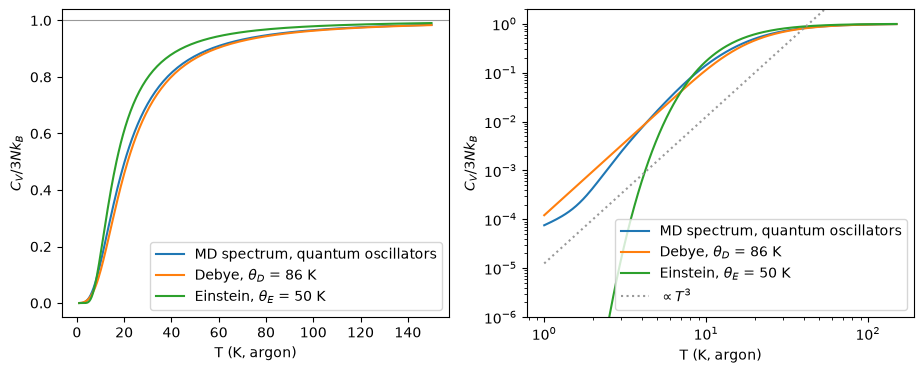

In [11]:
T = np.geomspace(1, 150, 200)                     # K, for argon
x = hbar_reduced*omega[1:, None]*119.8/T[None, :]  # hbar*omega/(k_B*T), from the first omega above 0
C_spectrum = np.trapezoid(g[1:, None]*x**2*np.exp(-x)/(1 - np.exp(-x))**2, omega[1:], axis=0)/(3*500)

theta_E = hbar_reduced*omega_E*119.8
C_einstein = (theta_E/T)**2*np.exp(-theta_E/T)/(1 - np.exp(-theta_E/T))**2
y = np.linspace(1e-6, 1, 400)[:, None]*(theta_D/T)[None, :]   # x from 0 to theta_D/T
C_debye = 3*(T/theta_D)**3*np.trapezoid(y**4*np.exp(-y)/(1 - np.exp(-y))**2, y, axis=0)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for ax in (left, right):
    ax.plot(T, C_spectrum, label="MD spectrum, quantum oscillators")
    ax.plot(T, C_debye, label=f"Debye, $\\theta_D$ = {theta_D:.0f} K")
    ax.plot(T, C_einstein, label=f"Einstein, $\\theta_E$ = {theta_E:.0f} K")
    ax.set_xlabel("T (K, argon)")
    ax.set_ylabel("$C_V / 3Nk_B$")
left.axhline(1, color="0.6", lw=0.8)
left.legend()
right.loglog(T, 1e-4*(T/2)**3, color="0.6", ls=":", label="$\\propto T^3$")
right.set_ylim(1e-6, 2)
right.legend()
plt.show()

At high temperature all three reach the classical value. At low temperature
(right, on logarithmic axes) Einstein's model drops exponentially, because all its
modes have the same frequency, while Debye's sound waves include arbitrarily low
frequencies and give the $T^3$ law. The simulated crystal follows Debye down to a
few kelvin and then drops away too: 500 atoms leave no room for sound waves longer
than the box, so its lowest vibration has a finite frequency, and like Einstein's
oscillators it freezes out. A larger crystal pushes this to lower temperatures.